In [1]:
import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
import pandas as pd
sys.path.append('../../')
from helper_function import *
plt.rcParams['font.family'] = 'Arial'
cobra.Configuration().solver = "glpk"

In [2]:
with open('../../FBAsolution/M9_sufficient_eccoli_proteome_weakbg.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_total_nutrient_count = data['all_total_nutrient_count']
    all_total_intake = data['all_total_intake']
    all_growth_rate = data['all_growth_rate'].reshape(-1)
    all_random_medium = data['all_random_medium']
    all_met_flux = data['all_met_flux'].reshape(-1)
    del data

In [ ]:
mapping_df = pd.read_csv(
    "iJO1366star_to_AGORA2_mapping.csv")

w_dict = {}
data = mapping_df[mapping_df['orientation'] == 'same'][mapping_df['match_status'].isin(['exact', 'high_similarity'])]
for ag_id, coeff in zip(data['agora_reaction_id'], data['prot_pool_coefficient']):
    w_dict[ag_id] = abs(coeff) * 1000 / 0.3

with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

/tmp/ipykernel_349459/2743879224.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data = mapping_df[mapping_df['orientation'] == 'same'][mapping_df['match_status'].isin(['exact', 'high_similarity'])]


In [4]:
def node_proteome_cost(met_flux, node_id, cluster_nodes):
        
    grouped_rec = [rec for rec in cluster_nodes[node_id] if 'EX_' not in rec]
    #grouped_flux = {rec: value for rec, value in met_flux if rec+'_fwd' in grouped_rec  or rec+'_bwd' in grouped_rec}

    grouped_flux = {rec: value for rec, value in met_flux if (rec+'_fwd' in grouped_rec and value > 0) or (rec+'_bwd' in grouped_rec and value < 0)}
    
    node_proteome_cost = 0
    for rec, flux in grouped_flux.items():
        proteome_cost = abs(flux)
        node_proteome_cost += proteome_cost

    return node_proteome_cost

def graph_node_proteome_cost(met_flux, cluster_nodes):
    graph_proteome_cost = {}

    for node_id in range(20):
        temp = node_proteome_cost(met_flux, node_id, cluster_nodes)
        graph_proteome_cost[node_id] = temp

    return graph_proteome_cost

In [5]:
def node_detailed_proteome_cost(met_flux, node_id, cluster_nodes):
        
    grouped_rec = [rec for rec in cluster_nodes[node_id] if 'EX_' not in rec]
    #grouped_flux = {rec: value for rec, value in met_flux if rec+'_fwd' in grouped_rec  or rec+'_bwd' in grouped_rec}

    #grouped_flux = {rec: value for rec, value in met_flux if (rec+'_fwd' in grouped_rec and value > 0) or (rec+'_bwd' in grouped_rec and value < 0)}
    grouped_flux = {rec: value * w_dict.get(rec, 1) for rec, value in met_flux if (rec+'_fwd' in grouped_rec and value > 0) or (rec+'_bwd' in grouped_rec and value < 0)}
    

    node_detailed = []

    for rec, flux in grouped_flux.items():
        proteome_cost = abs(flux)
        node_detailed.append((rec, node_id, proteome_cost))

    return node_detailed

def graph_detailed_proteome_cost(met_flux, cluster_nodes):
    graph_detailed_proteome_cost = []

    for node_id in range(20):
        temp = node_detailed_proteome_cost(met_flux, node_id, cluster_nodes)
        graph_detailed_proteome_cost.append(temp)

    return graph_detailed_proteome_cost

from itertools import chain
def build_reaction_flux_df(all_met_flux_species_list, cluster_nodes):
    n_species = len(all_met_flux_species_list)
    species_indices = range(n_species)
    reaction_flux = {}

    for sp_idx in species_indices:
        res = graph_detailed_proteome_cost(all_met_flux_species_list[sp_idx], cluster_nodes)
        if not res:
            continue
        if isinstance(res[0], tuple):
            triplets = res
        else:
            triplets = list(chain.from_iterable(res))

        total_flux = sum(
            flux
            for rxn, sector_idx, flux in triplets
        )

        for rxn, sector_idx, flux in triplets:
            reaction_fraction = flux / total_flux if total_flux != 0 else 0
            key = (rxn, sector_idx)
            if key not in reaction_flux:
                reaction_flux[key] = {}
            reaction_flux[key][sp_idx] = reaction_fraction #flux

    rows = []
    for (rxn, sector_idx), sp_flux in reaction_flux.items():
        flux_list = [sp_flux.get(sp_idx, 0) for sp_idx in species_indices]
        rows.append({
            "reaction": rxn,
            "Cluster": sector_idx,
            "flux_list": flux_list,
        })

    df_reaction_flux = pd.DataFrame(rows)
    return df_reaction_flux

df_flux = build_reaction_flux_df(all_met_flux, cluster_nodes)
combined_df = df_flux[df_flux["Cluster"] != 19].reset_index(drop=True)

In [6]:
from scipy.stats import spearmanr

flux_matrix = np.vstack(combined_df["flux_list"].tolist())
gr = all_growth_rate
od_env = np.array(gr)

combined_df["Corr"] = [spearmanr(row, od_env)[0] for row in flux_matrix] 


cluster_corrs = []

for cluster_id, indices in combined_df.groupby("Cluster").indices.items():

    expr_sum = flux_matrix[indices].sum(axis=0)

    if np.all(expr_sum == 0) or np.std(expr_sum) == 0:
        corr = 0.0 
    else:
        corr, _ = spearmanr(expr_sum, od_env)
    cluster_corrs.append(corr)

obs_mean = np.nanmean(np.abs(cluster_corrs))
obs_var = combined_df.groupby("Cluster")["Corr"].var().mean()

n_perm = 10000
random_means = []
random_vars = []

original_clusters = combined_df["Cluster"].values
n_samples = len(combined_df)

for _ in range(n_perm):
    shuffled_clusters = np.random.permutation(original_clusters)
    
    group_mapper = pd.Series(shuffled_clusters, index=combined_df.index)
    
    def calc_shuffled_corr(indices):
        group_sum = flux_matrix[indices].sum(axis=0)
        if np.std(group_sum) == 0:
            return 0.0
        return abs(spearmanr(group_sum, od_env)[0])

    grouped_indices = group_mapper.groupby(group_mapper).indices
    
    current_perm_corrs = [calc_shuffled_corr(idx) for idx in grouped_indices.values()]
    random_means.append(np.nanmean(current_perm_corrs))
    
    current_vars = combined_df["Corr"].groupby(group_mapper).var()
    random_vars.append(current_vars.mean())

Observed Mean: 0.5981, p-value: 0.0188, z-score: 2.03


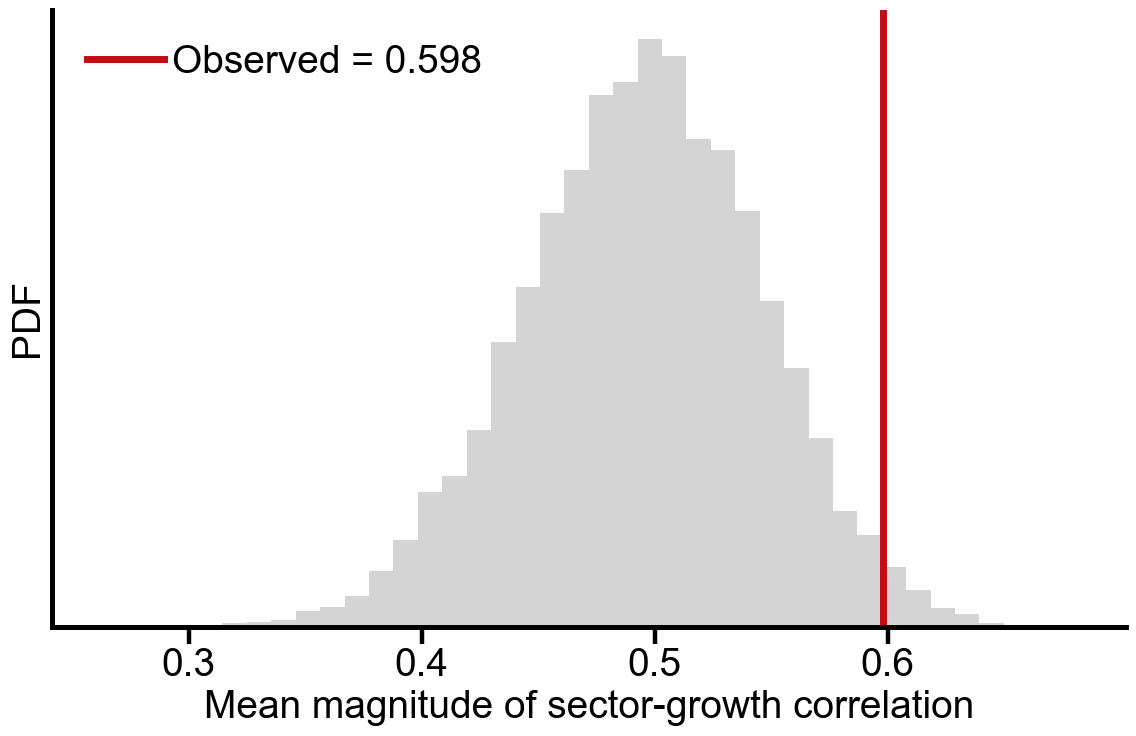

In [7]:
from matplotlib.ticker import MaxNLocator
set_panel_style(scale=4)

hist_color = "#D0D0D0"   # light gray
mean_line  = "#C40A13"   # deep red
var_line   = "#2F5597"   # deep blue

p_mean = (np.sum(np.array(random_means) >= obs_mean) + 1) / (n_perm + 1)
p_var  = (np.sum(np.array(random_vars)  <= obs_var)  + 1) / (n_perm + 1)
z_mean = (obs_mean - np.mean(random_means)) / np.std(random_means)
print(f"Observed Mean: {obs_mean:.4f}, p-value: {p_mean:.4f}, z-score: {z_mean:.2f}")

# ---------------- Figure 1: mean ----------------
fig, ax = plt.subplots(figsize=(12, 8))

ax.hist(random_means, bins=40, color=hist_color, alpha=0.9, edgecolor="none")
ax.axvline(obs_mean, color=mean_line, linewidth=5,
           label=rf"Observed = {obs_mean:.3f}")

ax.set_xlabel("Mean magnitude of sector-growth correlation")
ax.set_ylabel("PDF")
ax.legend(frameon=False, handletextpad=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xticks([0.3, 0.4, 0.5, 0.6])
ax.tick_params(axis="y", left=False, labelleft=False)

#ax.xaxis.set_major_locator(MaxNLocator(nbins=4))

plt.tight_layout()
#fig.savefig("Supp_figure6_ecoli_robust.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()